# Tugas Praktikum - Eksperimen Arsitektur dan Aktivasi JST pada Dataset PBL

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# 1. Load dataset PBL (50.000 baris)
df = pd.read_csv('burnout_dataset1.csv')
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in num_cols if c not in ['Person_ID', 'Burnout_Score']]

X_raw = SimpleImputer(strategy='median').fit_transform(df[feature_cols])
X = StandardScaler().fit_transform(X_raw)

encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(df[['Burnout_Risk']])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=df['Burnout_Risk'], random_state=42
)
print(f"Dimensi X_train: {X_train.shape}, X_test: {X_test.shape}, Kelas: {encoder.categories_[0]}")

# 2. Bangun model JST Baseline (2 Hidden Layer: 128, 64 ReLU)
tf.keras.utils.set_random_seed(42)
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(3, activation='softmax'),
])

# 3. Kompilasi model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 4. Latih model
t0 = time.time()
history_baseline = model.fit(
    X_train, y_train, epochs=15, batch_size=128, validation_split=0.1, verbose=1
)
t_train_baseline = time.time() - t0

# 5. Evaluasi model
loss_base, acc_base = model.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Baseline pada data uji: {acc_base:.4f}, Loss: {loss_base:.4f}")

Dimensi X_train: (40000, 19), X_test: (10000, 19), Kelas: ['High' 'Low' 'Moderate']
Epoch 1/15


  1/282 ━━━━━━━━━━━━━━━━━━━━ 3:49 817ms/step - accuracy: 0.3984 - loss: 1.0587

 21/282 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6879 - loss: 0.7585    

 44/282 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7392 - loss: 0.6165

 66/282 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7585 - loss: 0.5527

 90/282 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7707 - loss: 0.5152

... (193 outputs left out)

230/282 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8247 - loss: 0.3593

259/282 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8242 - loss: 0.3591

282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8258 - loss: 0.3569 - val_accuracy: 0.8045 - val_loss: 0.3879


Akurasi Baseline pada data uji: 0.8099, Loss: 0.3944


## Eksperimen Variasi Parameter

In [2]:
hasil_eksperimen = [{
    'Model': 'Baseline (2 Layer: 128, 64)',
    'Hidden Layers': 2,
    'Neuron': '[128, 64]',
    'Aktivasi': 'ReLU',
    'Waktu Latih (s)': round(t_train_baseline, 2),
    'Loss Uji': round(loss_base, 4),
    'Akurasi Uji': round(acc_base, 4),
}]


def run_experiment(name, layers_cfg, activation):
    tf.keras.utils.set_random_seed(42)
    layers = [Input(shape=(X_train.shape[1],))]
    for units in layers_cfg:
        layers.append(Dense(units, activation=activation))
    layers.append(Dense(3, activation='softmax'))

    m = Sequential(layers)
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    t_start = time.time()
    hist = m.fit(X_train, y_train, epochs=15, batch_size=128, validation_split=0.1, verbose=0)
    elapsed = time.time() - t_start
    l_test, a_test = m.evaluate(X_test, y_test, verbose=0)
    hasil_eksperimen.append({
        'Model': name,
        'Hidden Layers': len(layers_cfg),
        'Neuron': str(layers_cfg),
        'Aktivasi': activation.upper() if activation == 'relu' else activation.capitalize(),
        'Waktu Latih (s)': round(elapsed, 2),
        'Loss Uji': round(l_test, 4),
        'Akurasi Uji': round(a_test, 4),
    })
    return hist


h_256_128 = run_experiment('Variasi Neuron (2 Layer: 256, 128)', [256, 128], 'relu')
h_3layer = run_experiment('3 Hidden Layer (256, 128, 64)', [256, 128, 64], 'relu')
h_sigmoid = run_experiment('Sigmoid (2 Layer: 128, 64)', [128, 64], 'sigmoid')
h_sigmoid_3l = run_experiment('Sigmoid (3 Layer: 256, 128, 64)', [256, 128, 64], 'sigmoid')

df_eksperimen = pd.DataFrame(hasil_eksperimen)
df_eksperimen

,Model,Hidden Layers,Neuron,Aktivasi,Waktu Latih (s),Loss Uji,Akurasi Uji
0,"Baseline (2 Layer: 128, 64)",2,"[128, 64]",ReLU,12.25,0.3944,0.8099
1,"Variasi Neuron (2 Layer: 256, 128)",2,"[256, 128]",RELU,11.38,0.4090,0.8044
2,"3 Hidden Layer (256, 128, 64)",3,"[256, 128, 64]",RELU,12.17,0.4383,0.7959
3,"Sigmoid (2 Layer: 128, 64)",2,"[128, 64]",Sigmoid,11.06,0.3789,0.8165
4,"Sigmoid (3 Layer: 256, 128, 64)",3,"[256, 128, 64]",Sigmoid,13.83,0.3768,0.8165


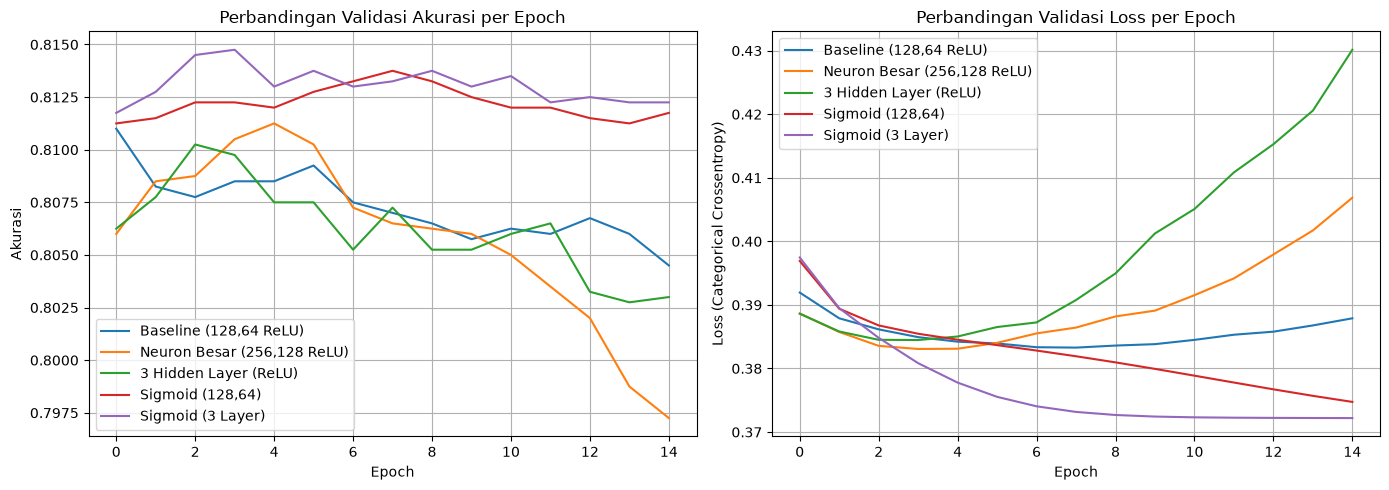

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Validasi Akurasi
axes[0].plot(history_baseline.history['val_accuracy'], label='Baseline (128,64 ReLU)')
axes[0].plot(h_256_128.history['val_accuracy'], label='Neuron Besar (256,128 ReLU)')
axes[0].plot(h_3layer.history['val_accuracy'], label='3 Hidden Layer (ReLU)')
axes[0].plot(h_sigmoid.history['val_accuracy'], label='Sigmoid (128,64)')
axes[0].plot(h_sigmoid_3l.history['val_accuracy'], label='Sigmoid (3 Layer)')
axes[0].set_title('Perbandingan Validasi Akurasi per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Akurasi')
axes[0].legend()
axes[0].grid(True)

# Plot Validasi Loss
axes[1].plot(history_baseline.history['val_loss'], label='Baseline (128,64 ReLU)')
axes[1].plot(h_256_128.history['val_loss'], label='Neuron Besar (256,128 ReLU)')
axes[1].plot(h_3layer.history['val_loss'], label='3 Hidden Layer (ReLU)')
axes[1].plot(h_sigmoid.history['val_loss'], label='Sigmoid (128,64)')
axes[1].plot(h_sigmoid_3l.history['val_loss'], label='Sigmoid (3 Layer)')
axes[1].set_title('Perbandingan Validasi Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss (Categorical Crossentropy)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Berdasarkan hasil eksperimen klasifikasi risiko burnout (Burnout_Risk) pada 50.000 data PBL menggunakan JST:

1. Peningkatan jumlah neuron dari [128, 64] menjadi [256, 128] serta penambahan hidden layer menjadi 3 layer ([256, 128, 64]) menambah jumlah parameter terlatih dan waktu komputasi per epoch.
2. Pada kurva validasi per epoch, model dengan fungsi aktivasi ReLU mencapai penurunan validation loss dan peningkatan validation accuracy lebih cepat pada epoch awal dibandingkan model dengan aktivasi Sigmoid, terutama pada arsitektur 3 layer.
3. Tabel perbandingan menampilkan ringkasan waktu latih, loss uji, dan akurasi uji dari kelima konfigurasi sehingga dapat dipilih kompromi terbaik antara akurasi dan efisiensi komputasi.